##**7.5 LSTM**

:RNN에서 가중치가 업데이트되는 과정에서 기울기가 1보다 작은 값이 계속 곱해지기 때문에 기울기가 사라지는 기울기 소멸 문제가 발생. 따라서 이를 해결하기 위한 방식

###**7.5.1 LSTM 구조**

**LSTM 순전파**

: LSTM은 기울기 소멸 문제를 해결하기 위해 망각 게이트, 입력 게이트, 출력 게이트라는 새로운 요소를 은닉층의 각 뉴런에 추가.

**망각 게이트**

: 과거 정보를 어느 정도 기억할지 결정.

- 과거 정보와 현재 데이터를 입력받아 시그모이드를 취한 후 그 값을 과거 정보에 곱함
- 따라서 시그모이드의 출력이 0이면 과거 정보는 버리고, 1이면 과거 정보는 온전히 보존

> 계산한 값이 1이면 바로 직전의 정보를 메모리에 유지. 0이면 초기화

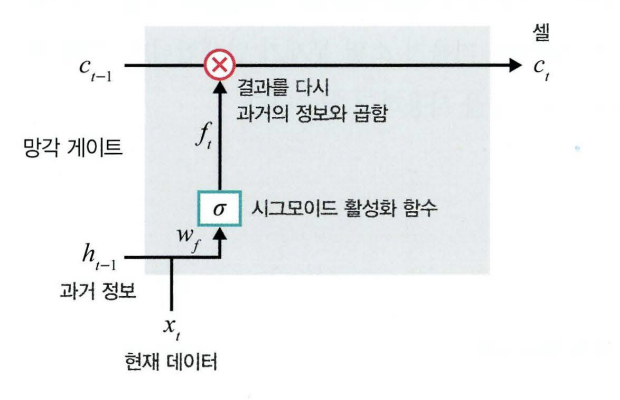

**입력 게이트**

: 현재 정보를 기억하기 위해 만들어짐. 과거 정보와 현재 데이터를 입력받아 시그모이드와 하이퍼볼릭 탄젠트 함수를 기반으로 현재 정보에 대한 보존량을 결정

> 즉, 현재 메모리에 새로운 정보를 반영할지 결정하는 역할을 함

- 계산한 값이 1이면 입력 x가 들어올 수 있도록 허용
- 계산한 값이 0이면 차단

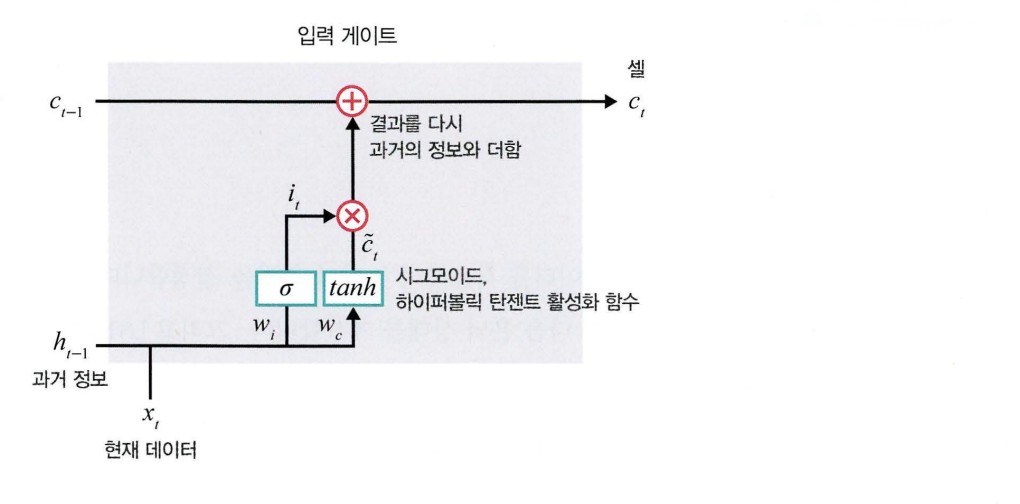

**셀**

: 각 단계에 대한 은닉 노드를 메모리 셀이라고 함. '총합'을 사용하여 셀 값을 반영하며, 이것으로 기울기 소멸 문제를 해결.

[셀 업데이트 방법]
- 망각 게이트와 입력 게이트의 이전 단계 셀 정보를 계산하여 현재 단계의 셀 상태를 업데이트

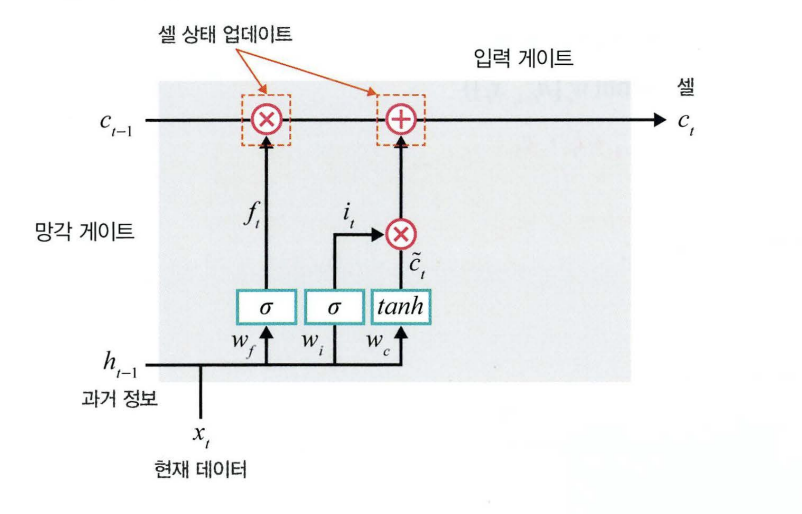

**출력 게이트**

: 과거 정보와 현재 데이터를 사용하여 뉴런의 출력을 결정.

- 이전 은닉 상태와 t번째 입력을 고려해서 다음 은닉 상태를 계산.
- 그리고 LSTM에서는 이 은닉 상태가 그 시점에서의 출력이 됨
- 계산한 값이 1이면 의미 있는 결과로 최종 출력
- 계산한 값이 0이면 해당 연산 출력을 하지 않음
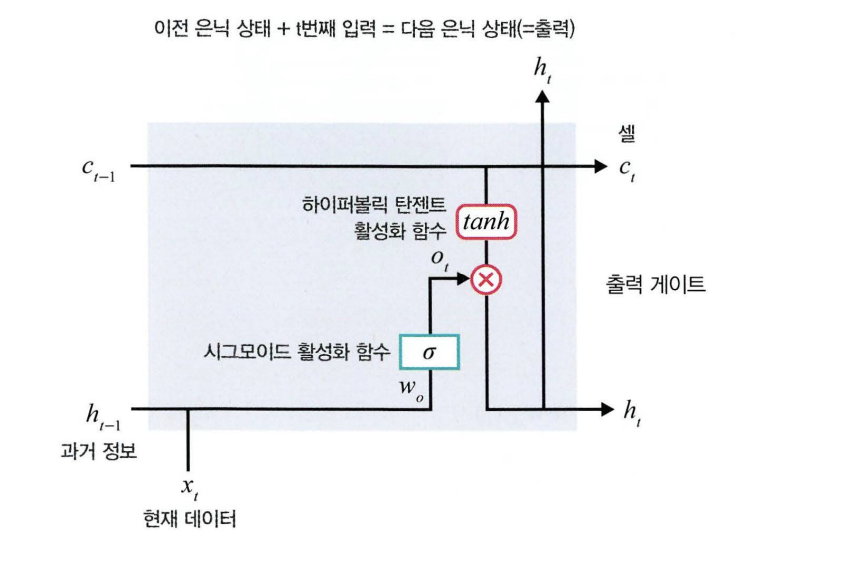

**LSTM 역전파**

: 셀을 통해 역전파를 수행하기 때문에 '중단 없는 기울기'라고도 함

> 즉, 최종 오차는 모든 노드에 전파되는데, 이때 셀을 통해 중단 없이 전파됨
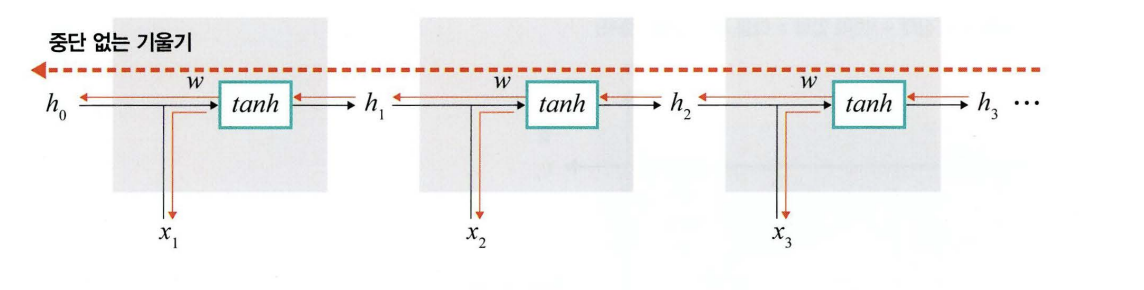

- 이때 주의해야 할 것은 셀 단위로 오차가 전파된다고 해서 입력 방향으로 오차가 전파되지 않는 것은 아님
- 셀 내부적으로는 오차가 입력으로 전파됨

<br>

###**7.5.2 LSTM 셀 구현**



In [1]:
# 라이브러리 호출
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as dataset
from torch.nn import Parameter   # 파라미터 목록을 가지고 있는 라이브러리(패키지)
from torch import Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader
import math   # 수학과 관련되어 다양한 함수들과 상수들이 정의되어 있는 라이브러리

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
cuda = True if torch.cuda.is_available() else False   # GPU 사용에 필요

Tensor = torch.cuda.FloatTensor if cuda else torch.FloatTensor   # GPU 사용에 필요

torch.manual_seed(125)
if torch.cuda.is_available():
  torch.cuda.manual_seed_all(125)

In [2]:
# 데이터 전처리
import torchvision.transforms as transforms

mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (1.0,)) # 평균을 0.5, 표준편차를 1.0으로 데이터 정규화
])



In [3]:
# 데이터셋 내려받기
from torchvision.datasets import MNIST

download_root = '../chap07/MNIST_DATASET'  ## MNIST를 내려받을 경로

train_dataset = MNIST(download_root, transform=mnist_transform, train=True,
                      download=True)
test_dataset = MNIST(download_root, transform=mnist_transform, train=False,
                     download=True)
valid_dataset = MNIST(download_root, transform=mnist_transform, train=False,
                      download=True)

100%|██████████| 9.91M/9.91M [00:00<00:00, 14.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 341kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.08MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.19MB/s]


[MNIST 데이터셋을 내려받기 위해 필요한 파라미터]
- download_root: MNIST를 내려받을 위치 지정
- transform: 앞에서 정의했던 데이터 전처리 적용
- train: TRUE로 설정할 경우 훈련용 데이터셋을 가져오지만, False로 설정할 경우 테스트용 데이터셋을 가져옴
- download: True로 설정될 경우 낼받으려는 위치에 MNIST 파일이 없으면 내려받지만 파일이 있다면 내려받지 않음

> train_loader, valid_loader, test_loader가 호출될 때 메모리로 불러온다는 점을 주의

In [4]:
# 데이터셋을 메모리로 가져오기
batch_size = 64
train_loader = DataLoader(dataset=train_dataset,
                          batch_size=batch_size,
                          shuffle=True)
valid_loader = DataLoader(dataset=valid_dataset,
                          batch_size=batch_size,
                          shuffle=True)
test_loader = DataLoader(dataset=test_dataset,
                         batch_size=batch_size,
                         shuffle=False)

In [5]:
# 변수 값 지정
batch_size = 100
n_iters = 6000
num_epochs = n_iters / (len(train_dataset) / batch_size)
num_epochs = int(num_epochs)

In [6]:
# LSTM 셀 네트워크 구축
class LSTMCell(nn.Module):
  def __init__(self, input_size, hidden_size, bias=True):
    super(LSTMCell, self).__init__()
    self.input_size = input_size
    self.hidden_size = hidden_size
    self.bias = bias
    self.x2h = nn.Linear(input_size, 4 * hidden_size, bias=bias)
    self.h2h = nn.Linear(hidden_size, 4 * hidden_size, bias=bias)
    self.reset_parameters()

  def reset_parameters(self): # 모델의 파라미터 초기화
    std = 1.0 / math.sqrt(self.hidden_size)
    for w in self.parameters():
      w.data.uniform_(-std, std)

  def forward(self, x, hidden):
    hx, cx = hidden
    x = x.view(-1, x.size(1))

    gates = self.x2h(x) + self.h2h(hx)
    gates = gates.squeeze()
    ingate, forgetgate, cellgate, outgate = gates.chunk(4,1)

    ingate = F.sigmoid(ingate)  # 입력 게이트에 시그모이드 활성화 함수 적용
    forgetgate = F.sigmoid(forgetgate)  # 망각 게이트에 시그모이드 활성화 함수 적용
    cellgate = F.tanh(cellgate)   # 셀 게이트에 탄젠트 활성화 함수 적용
    outgate = F.sigmoid(outgate)   # 출력 게이트에 시그모이드 활성화 함수 적용

    cy = torch.mul(cx, forgetgate) + torch.mul(ingate, cellgate)
    hy = torch.mul(outgate, F.tanh(cy))
    return(hy, cy)

- LSTM에서 중요한 것은 게이트. 게이트는 망각, 입력, 셀, 출력으로 구성되며 이 모든 게이트는 다음 코드처럼 구할 수 있음


```
gates = F.linear(input, w_ih, b_ih) + F.linear(hx, w_hh, b_hh)
```

- input: 입력층으로 입력되는 훈련 데이터셋의 특성 칼럼 수
- w_ih: 입력층과 은닉층 사이의 가중치
- b_ih: 입력층과 은닉층 사이의 바이어스
- hx: 은닉층의 뉴런/유닛 개수
- w_hh: 은닉층과 은닉층 사이의 가중치
- b_hh: 은닉층과 은닉층 사이의 바이어스

> 이렇게 계산된 게이트는 gates.chunk(4,1)에 의해 네 개로 쪼개져서 각각 망각, 입력, 셀, 출력 게이트를 의미하는 변수에 저장



```
ingate, forgetgate, cellgate, outgate = gates.chunk(4,1)
```

- 4: 텐서를 몇 개로 쪼갤지 설정
- 1: 어떤 차원을 기준으로 쪼갤지를 결정. dim=1이므로 열 단위로 텐서를 분할하겠다는 의미

<br>

- uniform()은 난수를 위해 사용.
- torch.squeeze()는 텐서의 차원을 줄이고자 할 때 사용
- 하나의 LSTM 셀을 통과하면 셀 상태와 은닉 상태가 출력으로 주어짐. 이때 셀 상태는 입력, 망각, 셀 게이트에 의해 계산되며, 은닉 상태는 출력 게이트에 의해 계산됨
- torch.mul()은 텐서에 곱셈을 할 때 사용


In [7]:
# LSTM 셀의 전반적인 네트워크
class LSTMModel(nn.Module):
  def __init__(self, input_dim, hidden_dim, layer_dim, output_dim, bias=True):
    super(LSTMModel, self).__init__()
    self.hidden_dim = hidden_dim   # 은닉층의 뉴런/유닛 개수

    self.layer_dim = layer_dim
    self.lstm = LSTMCell(input_dim, hidden_dim, layer_dim)
    self.fc = nn.Linear(hidden_dim, output_dim)

  def forward(self, x):
    if torch.cuda.is_available(): # GPU 사용 유무 확인
      h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())  # (은닉층의 계층 개수, 배치 크기, 은닉층의 뉴런 개수) 형태를 갖는 은닉 상태를 0으로 초기화
    else:
      h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

    if torch.cuda.is_available(): # GPU 사용 유무 확인
      c0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())  # (은닉층의 계층 개수, 배치 크기, 은닉층의 뉴런 개수) 향태를 갖는 셀 상태를 0으로 초기화
    else:
      c0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

    outs = []
    cn = c0[0,:,:]  # (은닉층의 계층 개수, 배치 크기, 은닉층의 뉴런 개수) 크기를 갖는 셀 상태에 대한 텐서
    hn = h0[0,:,:]   # (은닉층의 계층 개수, 배치 크기, 은닉층의 뉴런 개수) 크기를 갖는 은닉 상태에 대한 텐서

    for seq in range(x.size(1)): # LSTM 셀 계층을 반복해 쌓아 올림
      hn, cn = self.lstm(x[:, seq, :], (hn, cn)) # 은닉 상태와 셀 상태를 LSTMCell에 적용한 결과를 또다시 hn, cn에 저장
      outs.append(hn)

    out = outs[-1].squeeze()
    out = self.fc(out)
    return out


```
self.lstm = LSTM(input_dim, hidden_dim, layer_dim)
```

- input_dim: 입력에 대한 특성 수
- hidden_dim: 은닉층의 뉴런 개수
- layer_dim: 은닉층의 계층 개수

In [8]:
# 옵티마이저와 손실 함수 지정
input_dim = 28
hidden_dim = 128
layer_dim = 1
output_dim = 10

model = LSTMModel(input_dim, hidden_dim, layer_dim, output_dim)
if torch.cuda.is_available(): # GPU 사용 유무 확인
  model.cuda()
criterion = nn.CrossEntropyLoss()
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

In [10]:
# 모델 학습 및 성능 확인
from torch.autograd import Variable

seq_dim = 28
loss_list = []
iter = 0
for epoch in range(num_epochs):
  for i, (images, labels) in enumerate(train_loader): # 훈련 데이터셋을 이용한 모델 학습
    if torch.cuda.is_available(): # GPU 사용 확인
      images = Variable(images.view(-1, seq_dim, input_dim).cuda())
      labels = Variable(labels.cuda())
    else: # GPU를 사용하지 않기 때문에 else 구문이 실행
      images = Variable(images.view(-1, seq_dim, input_dim))
      labels = Variable(labels)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels) # 손실 함수를 이용하여 오차 계산

    if torch.cuda.is_available():
      loss.cuda()

    loss.backward()
    optimizer.step() # 파라미터 업데이트
    loss_list.append(loss.item())
    iter += 1

    if iter % 500 == 0: # 정확도 계산
      correct = 0
      total = 0
      for images, labels in valid_loader: # 검증 데이터셋을 이용한 모델 성능 검증

        if torch.cuda.is_available():
          images = Variable(images.view(-1, seq_dim, input_dim)).cuda()
        else:
          images = Variable(images.view(-1, seq_dim, input_dim))
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1) # 모델을 통과한 결과의 최댓값으로부터 예측 결과 가져오기

        total += labels.size(0)   # 총 레이블 수
        if torch.cuda.is_available():
          correct += (predicted.cpu() == labels.cpu()).sum()
        else:
          correct += (predicted == labels).sum()

      accuracy = 100 * correct / total
      print('Iteration: {}. Loss: {}. Accuracy: {}'.format(iter, loss.item(), accuracy))


Iteration: 500. Loss: 2.263226270675659. Accuracy: 18.860000610351562
Iteration: 1000. Loss: 0.816689670085907. Accuracy: 72.80000305175781
Iteration: 1500. Loss: 0.25882840156555176. Accuracy: 89.44999694824219
Iteration: 2000. Loss: 0.4955109655857086. Accuracy: 92.52999877929688
Iteration: 2500. Loss: 0.09147753566503525. Accuracy: 95.2699966430664
Iteration: 3000. Loss: 0.17723877727985382. Accuracy: 96.27999877929688
Iteration: 3500. Loss: 0.13459256291389465. Accuracy: 96.41999816894531
Iteration: 4000. Loss: 0.09214291721582413. Accuracy: 96.63999938964844
Iteration: 4500. Loss: 0.05778902396559715. Accuracy: 97.05999755859375
Iteration: 5000. Loss: 0.030874507501721382. Accuracy: 97.4000015258789
Iteration: 5500. Loss: 0.024441640824079514. Accuracy: 97.86000061035156
Iteration: 6000. Loss: 0.10702446103096008. Accuracy: 97.62000274658203
Iteration: 6500. Loss: 0.08552303165197372. Accuracy: 97.6500015258789
Iteration: 7000. Loss: 0.08662440627813339. Accuracy: 97.7399978637695

In [11]:
# 테스트 데이터셋을 이용한 모델 예측 성능 확인
def evaluate(model, val_iter):
  corrects, total, total_loss = 0, 0, 0
  model.eval()
  for images, labels in val_iter:
    if torch.cuda.is_available(): # GPU 사용 유무 확인
      images = Variable(images.view(-1, seq_dim, input_dim).cuda())
      labels = labels.cuda()
    else:
      images = Variable(images.view(-1, seq_dim, input_dim)).to(device)
      labels = labels.to(device)
    logit = model(images).to(device)
    loss = F.cross_entropy(logit, labels, reduction="sum")
    _, predicted = torch.max(logit.data, 1) # logit.data 텐서에서 최댓값의 인덱스를 반환
    total += labels.size(0)
    total_loss += loss.item()
    corrects += (predicted == labels).sum()

  avg_loss = total_loss / len(val_iter.dataset)
  avg_accuracy = corrects / total
  return avg_loss, avg_accuracy

In [12]:
# 모델 예측 성능 확인
test_loss, test_acc = evaluate(model, test_loader)
print("Test Loss: %5.2f | Test Accuracy: %5.2f" % (test_loss, test_acc))

Test Loss:  0.07 | Test Accuracy:  0.98


###**7.5.3 LSTM 계층 구현**


In [13]:
# 라이브러리 호출
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.autograd import Variable
from tqdm import tqdm_notebook
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [14]:
!git clone https://github.com/gilbutITbook/080289.git

Cloning into '080289'...
remote: Enumerating objects: 2278, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 2278 (delta 3), reused 2 (delta 2), pack-reused 2262 (from 2)
Receiving objects: 100% (2278/2278), 330.29 MiB | 29.64 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Updating files: 100% (2591/2591), done.


In [15]:
# 데이터셋 가져오기
data = pd.read_csv('080289/chap07/data/SBUX.csv')
print(data.dtypes)

Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object


- 데이터셋에 포함된 'Date' 칼럼을 인덱스로 사용하도록 함
- 데이터들이 숫자기이 때문에 임베딩이 필요하지 않지만 단어들로 구성된 데이터셋은 임베딩 과정을 거쳐야 함
- 날짜 칼럼은 임베딩 처리가 어려운 경우가 많은데, 날짜 칼럼을 인덱스로 처리하면 편리함


In [16]:
# 날짜 칼럼을 인덱스로 사용
data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True) # 'Date' 칼럼을 인덱스로 사용

In [17]:
# 데이터 형식 변경
data['Volume'] = data['Volume'].astype(float) # 데이터 형식을 변경할 때는 astype()을 사용

In [18]:
# 훈련과 레이블 분리
X = data.iloc[:, :-1]
y = data.iloc[:, 5:6]
print(X)
print(y)

                  Open        High         Low       Close   Adj Close
Date                                                                  
2019-12-11   86.260002   86.870003   85.849998   86.589996   84.145752
2019-12-12   88.000000   88.889999   87.540001   88.209999   85.720032
2019-12-13   88.019997   88.790001   87.580002   88.669998   86.167046
2019-12-16   89.139999   89.300003   88.430000   88.779999   86.273941
2019-12-17   88.870003   88.970001   87.470001   88.129997   85.642288
...                ...         ...         ...         ...         ...
2020-12-04  101.349998  102.940002  101.070000  102.279999  101.442787
2020-12-07  102.010002  102.220001  100.690002  101.410004  100.579918
2020-12-08  100.370003  101.570000  100.010002  101.209999  100.381554
2020-12-09  101.940002  102.209999  100.099998  100.400002   99.578186
2020-12-10  103.510002  106.089996  102.750000  105.389999  104.527336

[253 rows x 5 columns]
                Volume
Date                  
2019-12

- 데이터셋에서 데이터 간의 분포가 다르게 나타날 때 분포를 고르게 맞추기 위해 MinMaxScaler()와 StandardScaler()를 사용해 분산을 조정함

In [19]:
# 데이터 분포 조정
ms = MinMaxScaler()  # 데이터의 모든 값이 0~1 사이에 존재하도록 분산 조정
ss = StandardScaler()  # 데이터가 평균 0, 분산 1이 되도록 분산 조정

X_ss = ss.fit_transform(X)
y_ms = ms.fit_transform(y)

X_train = X_ss[:200, :]  # 훈련 데이터셋
X_test = X_ss[200:, :]  # 테스트 데이터셋

y_train = y_ms[:200, :]
y_test = y_ms[200:, :]

print("Training Shape", X_train.shape, y_train.shape)
print("Testing Shape", X_test.shape, y_test.shape)

Training Shape (200, 5) (200, 1)
Testing Shape (53, 5) (53, 1)


In [20]:
# 데이터셋의 형태 및 크기 조정
X_train_tensors = Variable(torch.Tensor(X_train)) # Variable로 감싸진 텐서는 .backward()가 호출될 때 자동으로 기울기가 계산
X_test_tensors = Variable(torch.Tensor(X_test))

y_train_tensors = Variable(torch.Tensor(y_train))
y_test_tensors = Variable(torch.Tensor(y_test))

X_train_tensors_f = torch.reshape(X_train_tensors, (X_train_tensors.shape[0],
                                                    1, X_train_tensors.shape[1]))
X_test_tensors_f = torch.reshape(X_test_tensors, (X_test_tensors.shape[0],
                                                  1, X_test_tensors.shape[1]))

print("Training Shape", X_train_tensors_f.shape, y_train_tensors.shape)
print("TestingShape", X_test_tensors_f.shape, y_test_tensors.shape)

Training Shape torch.Size([200, 1, 5]) torch.Size([200, 1])
TestingShape torch.Size([53, 1, 5]) torch.Size([53, 1])


- torch.reshape은 텐서의 형태를 바꿀 때 사용


In [21]:
# LSTM 네트워크
class LSTM(nn.Module):
  def __init__(self, num_classes, input_size, hidden_size, num_layers, seq_length):
    super(LSTM, self).__init__()
    self.num_classes = num_classes  # 클래스 개수
    self.num_layers = num_layers  # LSTM 계층의 개수
    self.input_size = input_size  # 입력 크기로 훈련 데이터셋의 칼럼 개수 의미
    self.hidden_size = hidden_size  # 은닉층의 뉴런 개수
    self.seq_length = seq_length  # 시퀀스 길이

    self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                        num_layers=num_layers, batch_first=True) # LSTM 계층
    self.fc_1 = nn.Linear(hidden_size, 128)  # 완전연결층
    self.fc = nn.Linear(128, num_classes) # 출력층
    self.relu = nn.ReLU()

  def forward(self, x):
    h_0 = Variable(torch.zeros(self.num_layers, x.size(0), self.hidden_size))  # 은닉 상태를 0으로 초기화
    c_0 = Variable(torch.zeros(self.num_layers, x.size(0), self.hidden_size))  # 셀 상태를 0으로 초기화
    output, (hn, cn) = self.lstm(x, (h_0, c_0))  # LSTM 계층에 은닉 상태와 셀 상태 적용
    hn = hn.view(-1, self.hidden_size)  # 완전연결층 적용을 위해 데이터의 형태 조정(1차원으로 조정)
    out = self.relu(hn)
    out = self.fc_1(out)
    out = self.relu(out)
    out = self.fc(out)
    return out

In [22]:
# 변수 값 설정
num_epochs = 1000 # 1000번의 에포크
learning_rate = 0.0001 # 학습률을 0.0001로 지정

input_size = 5    # 입력 데이터셋의 칼럼 개수
hidden_size = 2    # 은닉층의 뉴런/유닛 개수
num_layers = 1   # LSTM 계층의 개수

num_classes = 1  # 클래스 개수
model = LSTM(num_classes, input_size, hidden_size, num_layers, X_train_tensors_f.shape[1]) # 앞에서 정의한 값들을 이용하여 LSTM 모델 학습

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [23]:
# 모델 학습
for epoch in range(num_epochs):
  outputs = model.forward(X_train_tensors_f)  # 전방향 학습
  optimizer.zero_grad()
  loss = criterion(outputs, y_train_tensors)  # 손실함수를 이용한 오차 계산(모델 학습 결과(outputs)와 레이블(y_train_tensors)의 차이 계산)
  loss.backward()  # 기울기 계산

  optimizer.step()  # 오차 업데이트
  if epoch % 100 == 0: # 1000을 100으로 나누어 나머지가 0이면 출력
    print("Epoch: %d, loss: %1.5f" % (epoch,loss.item()))

Epoch: 0, loss: 0.16316
Epoch: 100, loss: 0.05277
Epoch: 200, loss: 0.03839
Epoch: 300, loss: 0.03723
Epoch: 400, loss: 0.03563
Epoch: 500, loss: 0.03252
Epoch: 600, loss: 0.02863
Epoch: 700, loss: 0.02483
Epoch: 800, loss: 0.02200
Epoch: 900, loss: 0.02006


In [24]:
# 모델 예측 결과를 출력하기 위한 데이터 크기 재구성
df_x_ss = ss.transform(data.iloc[:, :-1]) # 데이터 정규화 (분포 조정)
df_y_ms = ms.transform(data.iloc[:, -1:]) # 데이터 정규화

df_x_ss = Variable(torch.Tensor(df_x_ss))
df_y_ms = Variable(torch.Tensor(df_y_ms))
df_x_ss = torch.reshape(df_x_ss, (df_x_ss.shape[0], 1, df_x_ss.shape[1]))

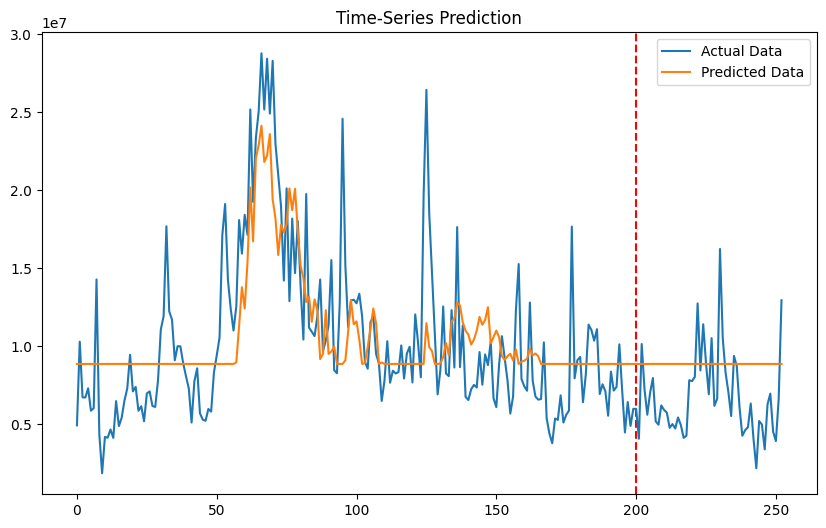

In [25]:
# 모델 예측 결과 출력
train_predict = model(df_x_ss)
predicted = train_predict.data.numpy()
label_y = df_y_ms.data.numpy()

predicted = ms.inverse_transform(predicted)  ## 모델 학습을 위해 전처리(정규화)했던 것을 해제해 그래프의 본래 값을 출력
label_y = ms.inverse_transform(label_y)
plt.figure(figsize=(10,6))
plt.axvline(x=200, c='r', linestyle='--')

plt.plot(label_y, label='Actual Data')
plt.plot(predicted, label='Predicted Data')
plt.title('Time-Series Prediction')
plt.legend()
plt.show()

- axvline()은 그래프의 축을 따라 수직선을 표현할 때 사용


```
plt.axvline(x=200, c='r', linestyle='--')
```
- x=200: 어떤 지점에 수직선을 표현할지 지정
- c: 어떤 색상으로 수직선을 표현할지 지정
- linestyle: 어떤 스타일로 수직선을 표현할지 지정

> 파란색은 실제 레이블에 대한 출력 결과이고 주확색은 모델이 예측한 결과를 보여줌. 예측 결과가 별로임.
